### 🏠 Robust Regression Engine

##### 📦 Setup: Libraries Import

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings band karne ke liye
import warnings
warnings.filterwarnings("ignore")

# Model selection tools
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV,
                                     KFold, StratifiedKFold, LeaveOneOut, TimeSeriesSplit)

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

# Models
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

🧠 Part A: Conceptual Foundation (Theory)

1. What is Regularization? Why is it needed?
Regularization adds a penalty term to the loss function to keep model coefficients small. It is needed to control overfitting, so the model performs well on unseen data and not only on training data.

2. Ridge (L2) vs Lasso (L1)

Ridge adds the squared size of coefficients as penalty. It shrinks coefficients towards zero but never makes them exactly zero.
Lasso adds the absolute size of coefficients as penalty. It can make some coefficients exactly zero, so it also does feature selection.

3. What is Cross-Validation and why is it important?
Cross-validation splits the data into several parts and trains and tests the model on different parts in turns. It gives a more reliable estimate of performance than a single train-test split and helps detect overfitting.

4. Cross-validation techniques

K-Fold: data is split into K equal folds. Each fold is used once as validation and the rest as training.
Stratified K-Fold: like K-Fold, but every fold keeps the same distribution of classes (or target bins for regression).
Leave-One-Out (LOOCV): only 1 sample is used for validation and all others for training. It repeats for every sample, so it is very slow on big data.
Time Series Split: the training data always comes before the validation data in time. Future data is never used to predict the past.

5. Why are tree-based models less sensitive to feature scaling?
Trees split data using threshold comparisons (e.g., area_sqft < 1500). These splits depend only on the order of values, not on their size, so scaling does not change the result.

##### 🧪 Part B: Dataset Understanding & Preparation
🔹 Task 6: Identify Features and Target Variable

In [2]:
# Dataset load karo
df = pd.read_csv("../Data/Advanced_Regression.csv")

# Pehli 5 rows dekho
print(df.head())

# Shape aur data types
print("Shape:", df.shape)
print(df.info())

# Missing values check
print("Missing values:\n", df.isnull().sum())

# sale_date ko date format me convert karo (time series ke liye chahiye)
df["sale_date"] = pd.to_datetime(df["sale_date"])

# Target variable
target = "house_price_inr"

# Features (property_id aur sale_date model ke feature nahi hain)
features = ["area_sqft", "bedrooms", "bathrooms", "location_score", "property_age",
            "distance_city_km", "near_school", "near_metro", "crime_rate_index"]

X = df[features]   # input
y = df[target]     # output

print("Features:", features)
print("Target:", target)

   property_id   sale_date  area_sqft  bedrooms  bathrooms  location_score  \
0       200001  2014-01-01       2181         6          4             8.1   
1       200002  2019-12-01       2383         5          4             5.3   
2       200003  2016-10-01       1047         3          3             5.9   
3       200004  2013-03-01       1753         4          3             7.0   
4       200005  2013-07-01       1728         4          4            10.0   

   property_age  distance_city_km  near_school  near_metro  crime_rate_index  \
0            21               3.8            0           0              4.84   
1            28              10.9            1           1              2.89   
2             7              27.5            0           1              4.04   
3            27              12.1            0           0              3.28   
4            32               1.4            0           1              3.84   

   house_price_inr  
0         35154898  
1       

📝 Note: Dataset mein alag se "renovation" column nahi hai. property_age hi age ki detail deta hai. property_id sirf ID hai, isliye drop kiya. sale_date ko Part D (Time Series Split) mein use karenge.

##### 🔹 Task 7: Train–Test Split

In [3]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)

Train size: (3040, 9)
Test size : (760, 9)


##### 🔹 Task 8: Basic Preprocessing (Scaling)

In [4]:
# Scaler banao
scaler = StandardScaler()

# fit sirf train data par (test par sirf transform, warna data leakage hoga)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done ✅")

Scaling done ✅


📝 Note: Scaling Ridge, Lasso aur SVR ke liye zaroori hai. Tree models ko iski zaroorat nahi. Aage Cross-Validation mein hum Pipeline use karenge taaki har fold mein scaling sahi tarike se ho.

##### 🛠️ Helper Function (Part G ke liye results store karna)

In [5]:
# Saare models ke results yaha store honge
results = []
trained_models = {}

def evaluate_model(name, model, family):
    """Model ko train aur test data par evaluate karke results list me daalta hai"""
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Family": family,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
    })
    trained_models[name] = model

##### 📉 Part C: Regularized Linear Models
🔹 Task 9: Implement Ridge Regression (L2)

In [6]:
# Ridge model (alpha abhi default 1.0)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

print("Ridge Train R2:", ridge.score(X_train_scaled, y_train))
print("Ridge Test R2 :", ridge.score(X_test_scaled, y_test))

Ridge Train R2: 0.9161854041282822
Ridge Test R2 : 0.91872594918288


##### 🔹 Task 10: Implement Lasso Regression (L1)

In [7]:
# Lasso model (alpha abhi default 1.0)
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

print("Lasso Train R2:", lasso.score(X_train_scaled, y_train))
print("Lasso Test R2 :", lasso.score(X_test_scaled, y_test))

Lasso Train R2: 0.9161856554542243
Lasso Test R2 : 0.9187436162999829


##### 🔹 Task 11: Tune Regularization Parameter (α) using Cross-Validation

In [8]:
# Alpha values ki range (target bahut bada hai, isliye alpha range badi rakhi)
alpha_values = np.logspace(-1, 6, 15)

# Pipeline: pehle scaling, fir model
ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=10000))])

# Ridge ke liye GridSearch (5-fold CV)
ridge_grid = GridSearchCV(ridge_pipe, {"model__alpha": alpha_values},
                          cv=5, scoring="neg_root_mean_squared_error")
ridge_grid.fit(X_train, y_train)

# Lasso ke liye GridSearch (5-fold CV)
lasso_grid = GridSearchCV(lasso_pipe, {"model__alpha": alpha_values},
                          cv=5, scoring="neg_root_mean_squared_error")
lasso_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Lasso alpha:", lasso_grid.best_params_)

# Best models save karo
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

# Results list me daalo
evaluate_model("Ridge (tuned)", best_ridge, "Regularized Linear")
evaluate_model("Lasso (tuned)", best_lasso, "Regularized Linear")

Best Ridge alpha: {'model__alpha': np.float64(1.0)}
Best Lasso alpha: {'model__alpha': np.float64(10000.0)}


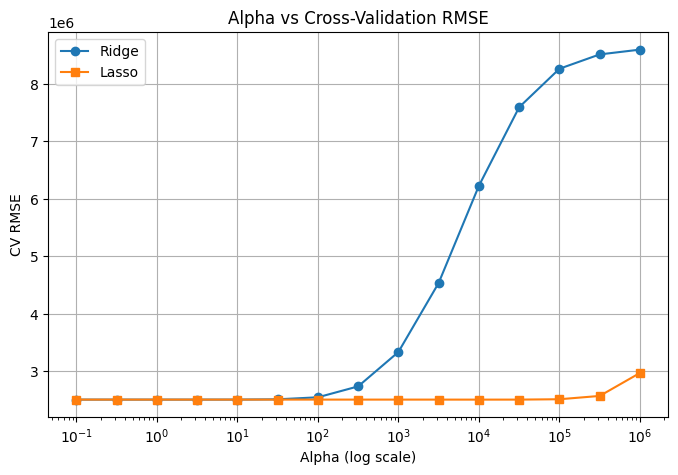

In [9]:
# 📊 Alpha vs CV RMSE chart
plt.figure(figsize=(8, 5))
plt.semilogx(alpha_values, -ridge_grid.cv_results_["mean_test_score"], marker="o", label="Ridge")
plt.semilogx(alpha_values, -lasso_grid.cv_results_["mean_test_score"], marker="s", label="Lasso")
plt.xlabel("Alpha (log scale)")
plt.ylabel("CV RMSE")
plt.title("Alpha vs Cross-Validation RMSE")
plt.legend()
plt.grid(True)
plt.show()

📝 Interpretation: Jaha curve sabse neeche hai, wahi best alpha hai. Bahut chhota alpha = kam regularization (overfitting ka risk). Bahut bada alpha = zyada regularization (underfitting ka risk).

##### 🔹 Task 12: Compare Ridge and Lasso

In [10]:
# Training error, Validation (CV) error, Test error
comparison = pd.DataFrame({
    "Model": ["Ridge", "Lasso"],
    "Training RMSE": [np.sqrt(mean_squared_error(y_train, best_ridge.predict(X_train))),
                      np.sqrt(mean_squared_error(y_train, best_lasso.predict(X_train)))],
    "Validation RMSE (CV)": [-ridge_grid.best_score_, -lasso_grid.best_score_],
    "Test RMSE": [np.sqrt(mean_squared_error(y_test, best_ridge.predict(X_test))),
                  np.sqrt(mean_squared_error(y_test, best_lasso.predict(X_test)))]
})
print(comparison)

   Model  Training RMSE  Validation RMSE (CV)     Test RMSE
0  Ridge   2.500609e+06          2.509016e+06  2.558402e+06
1  Lasso   2.500733e+06          2.508613e+06  2.560424e+06


            Feature    Ridge Coef    Lasso Coef
0         area_sqft  6.937545e+06  6.938214e+06
1          bedrooms  2.973655e+05  2.907946e+05
2         bathrooms  2.853268e+05  2.801473e+05
3    location_score  3.676865e+06  3.673262e+06
4      property_age -6.513024e+05 -6.422511e+05
5  distance_city_km -3.016962e+04 -2.254400e+04
6       near_school  1.697147e+04  6.554514e+03
7        near_metro  5.820432e+04  4.825058e+04
8  crime_rate_index -1.354728e+05 -1.260846e+05


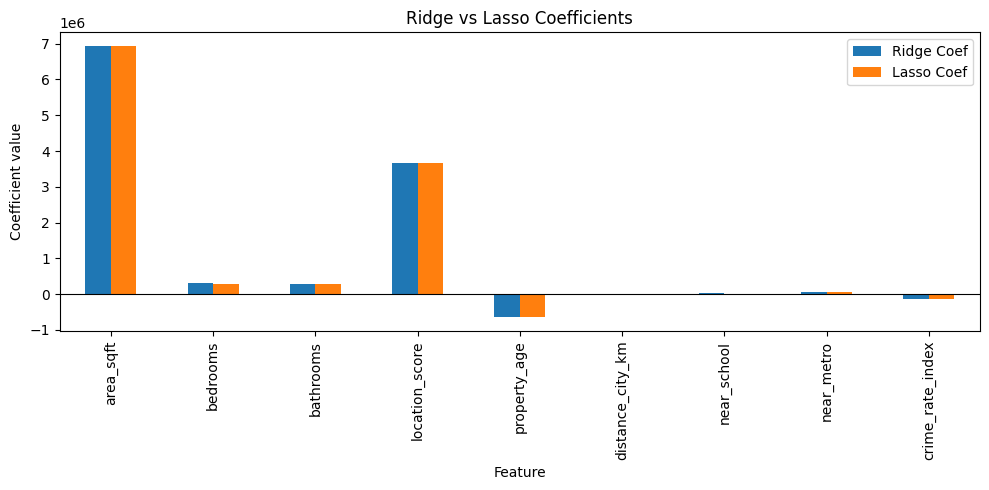

In [11]:
# Feature coefficient behavior
coef_df = pd.DataFrame({
    "Feature": features,
    "Ridge Coef": best_ridge.named_steps["model"].coef_,
    "Lasso Coef": best_lasso.named_steps["model"].coef_
})
print(coef_df)

# 📊 Coefficients ka bar chart
coef_df.set_index("Feature").plot(kind="bar", figsize=(10, 5))
plt.title("Ridge vs Lasso Coefficients")
plt.ylabel("Coefficient value")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

📝 Note: Dekho Lasso ke kaunse coefficients 0 ho gaye. Wo features Lasso ne unimportant maane. Ridge sab coefficients ko chhota karta hai par zero nahi karta.

##### 🔁 Part D: Cross-Validation Strategies
🔹 Task 13: Apply and Compare CV Techniques

In [12]:
cv_results = {}   # Har technique ka result yaha store hoga
model = best_ridge

① K-Fold

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
cv_results["K-Fold"] = (-scores.mean(), scores.std())
print("K-Fold RMSE:", -scores.mean())

K-Fold RMSE: 2511669.9995738147


② Stratified K-Fold (target values ko bins mein baant ke)

In [14]:
# Price ko 5 bins me todo (quantile based)
y_bins = pd.qcut(y_train, q=5, labels=False)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
splits = list(skf.split(X_train, y_bins))   # bins ke basis par split

scores = cross_val_score(model, X_train, y_train, cv=splits, scoring="neg_root_mean_squared_error")
cv_results["Stratified K-Fold"] = (-scores.mean(), scores.std())
print("Stratified K-Fold RMSE:", -scores.mean())

Stratified K-Fold RMSE: 2508709.1272196346


③ Leave-One-Out (LOOCV)

In [15]:
# LOOCV bahut slow hota hai, isliye sirf 500 rows ka sample lete hain
X_small = X_train.sample(500, random_state=42)
y_small = y_train.loc[X_small.index]

scores = cross_val_score(model, X_small, y_small, cv=LeaveOneOut(),
                         scoring="neg_mean_squared_error")
loo_rmse = np.sqrt(-scores.mean())
cv_results["LOOCV (500 rows)"] = (loo_rmse, np.nan)
print("LOOCV RMSE:", loo_rmse)

LOOCV RMSE: 2566736.3941567466


📝 Note: LOOCV mein har fold mein sirf 1 sample hota hai, isliye R² nahi nikal sakte. Hum MSE ka average lekar RMSE banate hain. Std bhi nahi dikhta (NaN).

④ Time Series Split (sale_date ke basis par)

In [16]:
# Data ko date ke order me sort karo
df_sorted = df.sort_values("sale_date")
X_ts = df_sorted[features]
y_ts = df_sorted[target]

tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(model, X_ts, y_ts, cv=tscv, scoring="neg_root_mean_squared_error")
cv_results["Time Series Split"] = (-scores.mean(), scores.std())
print("Time Series RMSE:", -scores.mean())

Time Series RMSE: 2524352.378566604


                      Mean RMSE       Std Dev
K-Fold             2.511670e+06  86145.861076
Stratified K-Fold  2.508709e+06  77987.041165
LOOCV (500 rows)   2.566736e+06           NaN
Time Series Split  2.524352e+06  78805.437087


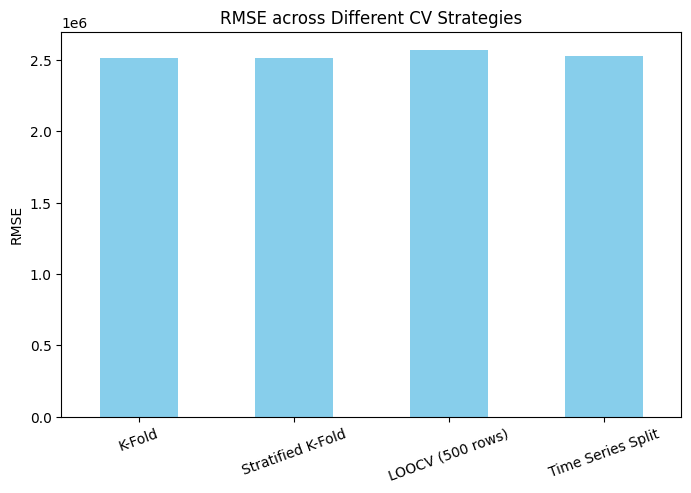

In [17]:
# Comparison table
cv_table = pd.DataFrame(cv_results, index=["Mean RMSE", "Std Dev"]).T
print(cv_table)

# 📊 Chart
cv_table["Mean RMSE"].plot(kind="bar", figsize=(8, 5), color="skyblue")
plt.title("RMSE across Different CV Strategies")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.show()

##### 🔹 Task 14: Analyze how metrics vary across CV strategies

📝 Note (run karne ke baad apne numbers ke saath likho):

- K-Fold aur Stratified K-Fold ke RMSE aamtaur par kareeb hote hain.
- Time Series Split ka RMSE alag aa sakta hai, kyunki training data chhota hota hai aur future data par test hota hai.
- LOOCV sabse slow hai, aur sirf 500 rows ka sample use hua hai.
- Std Dev jitna kam, model utna stable.

##### 🌳 Part E: Tree-Based Regression Models
🔹 Task 15: Decision Tree Regression

In [18]:
# Basic Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

# Predictions
dt_train_pred = dt_model.predict(X_train)
dt_test_pred = dt_model.predict(X_test)

# Evaluation
dt_train_rmse = np.sqrt(mean_squared_error(y_train, dt_train_pred))
dt_test_rmse = np.sqrt(mean_squared_error(y_test, dt_test_pred))
dt_test_mae = mean_absolute_error(y_test, dt_test_pred)
dt_test_r2 = r2_score(y_test, dt_test_pred)

print(f"Decision Tree (Default) - Train RMSE: {dt_train_rmse:,.2f}")
print(f"Decision Tree (Default) - Test RMSE:  {dt_test_rmse:,.2f}")
print(f"Decision Tree (Default) - Test MAE:   {dt_test_mae:,.2f}")
print(f"Decision Tree (Default) - Test R2:    {dt_test_r2:.4f}")

Decision Tree (Default) - Train RMSE: 0.00
Decision Tree (Default) - Test RMSE:  3,379,144.95
Decision Tree (Default) - Test MAE:   2,480,762.05
Decision Tree (Default) - Test R2:    0.8582


Note: Default Decision Tree bina rok-tok ke bahut deep ban sakta hai, jisse training error bahut kam aur test error zyada aata hai (overfitting).

##### Task 16: Control Tree Complexity Using Hyperparameters (max_depth, min_samples)

In [19]:
# Tuned Decision Tree to control overfitting
dt_tuned = DecisionTreeRegressor(
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
)
dt_tuned.fit(X_train, y_train)

dt_tuned_train_pred = dt_tuned.predict(X_train)
dt_tuned_test_pred = dt_tuned.predict(X_test)

print(
    f"Tuned DT - Train RMSE: {np.sqrt(mean_squared_error(y_train, dt_tuned_train_pred)):,.2f}"
)
print(
    f"Tuned DT - Test RMSE:  {np.sqrt(mean_squared_error(y_test, dt_tuned_test_pred)):,.2f}"
)
print(f"Tuned DT - Test MAE:   {mean_absolute_error(y_test, dt_tuned_test_pred):,.2f}")
print(f"Tuned DT - Test R2:    {r2_score(y_test, dt_tuned_test_pred):.4f}")

Tuned DT - Train RMSE: 2,437,399.97
Tuned DT - Test RMSE:  2,866,278.12
Tuned DT - Test MAE:   2,115,479.50
Tuned DT - Test R2:    0.8980


Note: max_depth tree ki height rokti hai, aur min_samples_split / min_samples_leaf chhote/noisy splits ko banne se rokte hain.

##### Task 17: Implement Random Forest Regression

In [20]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

print(
    f"Random Forest - Train RMSE: {np.sqrt(mean_squared_error(y_train, rf_train_pred)):,.2f}"
)
print(
    f"Random Forest - Test RMSE:  {np.sqrt(mean_squared_error(y_test, rf_test_pred)):,.2f}"
)
print(f"Random Forest - Test MAE:   {mean_absolute_error(y_test, rf_test_pred):,.2f}")
print(f"Random Forest - Test R2:    {r2_score(y_test, rf_test_pred):.4f}")

Random Forest - Train RMSE: 1,387,280.21
Random Forest - Test RMSE:  2,407,680.80
Random Forest - Test MAE:   1,773,376.75
Random Forest - Test R2:    0.9280


Note: Random Forest bahut saare decision trees ka average leta hai (bagging + random feature selection), jisse variance aur overfitting kam hota hai.

##### Task 18: Compare Single-Tree vs. Ensemble Performance

In [21]:
tree_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree (Default)",
        "Decision Tree (Tuned)",
        "Random Forest",
    ],
    "Train RMSE": [
        np.sqrt(mean_squared_error(y_train, dt_train_pred)),
        np.sqrt(mean_squared_error(y_train, dt_tuned_train_pred)),
        np.sqrt(mean_squared_error(y_train, rf_train_pred)),
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, dt_test_pred)),
        np.sqrt(mean_squared_error(y_test, dt_tuned_test_pred)),
        np.sqrt(mean_squared_error(y_test, rf_test_pred)),
    ],
    "Test MAE": [
        mean_absolute_error(y_test, dt_test_pred),
        mean_absolute_error(y_test, dt_tuned_test_pred),
        mean_absolute_error(y_test, rf_test_pred),
    ],
    "Test R2": [
        r2_score(y_test, dt_test_pred),
        r2_score(y_test, dt_tuned_test_pred),
        r2_score(y_test, rf_test_pred),
    ],
})

print(tree_comparison.to_string(index=False))

                  Model   Train RMSE    Test RMSE     Test MAE  Test R2
Decision Tree (Default) 0.000000e+00 3.379145e+06 2.480762e+06 0.858216
  Decision Tree (Tuned) 2.437400e+06 2.866278e+06 2.115480e+06 0.897988
          Random Forest 1.387280e+06 2.407681e+06 1.773377e+06 0.928020


Note: Single Decision Tree ka interpretation aasan hota hai, par Random Forest aam taur par zyada stable aur accurate test predictions deta hai.

##### Part F: Support Vector Regression

##### Task 19: Implement SVR with Linear and RBF/Polynomial Kernels

In [22]:
# SVR ke liye scaled features (X_train_scaled, X_test_scaled) use karna best rehta hai
svr_linear = SVR(kernel="linear", C=100000, epsilon=100000)
svr_linear.fit(X_train_scaled, y_train)
svr_lin_pred = svr_linear.predict(X_test_scaled)

svr_rbf = SVR(kernel="rbf", C=1000000, gamma="scale", epsilon=100000)
svr_rbf.fit(X_train_scaled, y_train)
svr_rbf_pred = svr_rbf.predict(X_test_scaled)

print(
    f"SVR (Linear) - Test RMSE: {np.sqrt(mean_squared_error(y_test, svr_lin_pred)):,.2f} | R2: {r2_score(y_test, svr_lin_pred):.4f}"
)
print(
    f"SVR (RBF)    - Test RMSE: {np.sqrt(mean_squared_error(y_test, svr_rbf_pred)):,.2f} | R2: {r2_score(y_test, svr_rbf_pred):.4f}"
)

SVR (Linear) - Test RMSE: 2,608,505.09 | R2: 0.9155
SVR (RBF)    - Test RMSE: 2,886,698.42 | R2: 0.8965


Note: Kyunki house_price_inr crores/lakhs mein hai, C aur epsilon ke values target ke scale ke hisab se bade rakhne padte hain. (Agar aapne y ko scale ya log-transform kiya hai, to C aur epsilon us scale ke hisab se set karein).

##### Task 20: Tune Hyperparameters ($C$, $\gamma$, $\varepsilon$)

In [ ]:
param_grid = {
    "kernel": ["rbf"],
    "C": [1e5, 5e5, 1e6, 5e6],
    "gamma": ["scale", 0.01, 0.1],
    "epsilon": [5e4, 1e5, 5e5],
}

grid_svr = GridSearchCV(
    SVR(),
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid_svr.fit(X_train_scaled, y_train)

best_svr = grid_svr.best_estimator_
best_svr_pred = best_svr.predict(X_test_scaled)

print("Best SVR Params:", grid_svr.best_params_)
print(
    f"Tuned SVR - Test RMSE: {np.sqrt(mean_squared_error(y_test, best_svr_pred)):,.2f}"
)
print(f"Tuned SVR - Test MAE:  {mean_absolute_error(y_test, best_svr_pred):,.2f}")
print(f"Tuned SVR - Test R2:   {r2_score(y_test, best_svr_pred):.4f}")

Best SVR Params: {'C': 5000000.0, 'epsilon': 50000.0, 'gamma': 0.01, 'kernel': 'rbf'}
Tuned SVR - Test RMSE: 2,321,340.83
Tuned SVR - Test MAE:  1,690,618.65
Tuned SVR - Test R2:   0.9331


Note: C penalty control karta hai, gamma RBF curve ka spread decide karta hai, aur epsilon margin width define karta hai jiske andar error ignore hota hai.

##### Task 21: Compare SVR Performance with Linear and Tree-Based Models

In [24]:
svr_compare = pd.DataFrame({
    "Model": ["SVR (Linear)", "SVR (RBF Tuned)", "Random Forest"],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, svr_lin_pred)),
        np.sqrt(mean_squared_error(y_test, best_svr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_test_pred)),
    ],
    "Test MAE": [
        mean_absolute_error(y_test, svr_lin_pred),
        mean_absolute_error(y_test, best_svr_pred),
        mean_absolute_error(y_test, rf_test_pred),
    ],
    "Test R2": [
        r2_score(y_test, svr_lin_pred),
        r2_score(y_test, best_svr_pred),
        r2_score(y_test, rf_test_pred),
    ],
})

print(svr_compare.to_string(index=False))

          Model    Test RMSE     Test MAE  Test R2
   SVR (Linear) 2.608505e+06 1.961691e+06 0.915511
SVR (RBF Tuned) 2.321341e+06 1.690619e+06 0.933090
  Random Forest 2.407681e+06 1.773377e+06 0.928020


Note: RBF SVR non-linear relationships pakad sakta hai, lekin hyperparameter tuning ke bina yeh easily underfit ya overfit ho sakta hai.

##### Part G: Model Comparison & Evaluation

##### Task 22 & Task 23: Evaluate All Models (MSE, MAE, RMSE, $R^2$) and Compare Model Families

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models_preds = {
    "Ridge (Tuned)": (best_ridge.predict(X_test), y_test),
    "Lasso (Tuned)": (best_lasso.predict(X_test), y_test),
    "Decision Tree (Tuned)": (dt_tuned.predict(X_test), y_test),
    "Random Forest": (rf_model.predict(X_test), y_test),
    "SVR (Tuned)": (best_svr.predict(X_test_scaled), y_test),
}

rows = []
for name, (pred, actual) in models_preds.items():
  mse = mean_squared_error(actual, pred)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(actual, pred)
  r2 = r2_score(actual, pred)
  rows.append({
      "Model": name,
      "MSE": mse,
      "RMSE": rmse,
      "MAE": mae,
      "R2": r2,
  })

eval_df = pd.DataFrame(rows).sort_values(by="RMSE")
print(eval_df.to_string(index=False))

                Model          MSE         RMSE          MAE       R2
          SVR (Tuned) 5.388623e+12 2.321341e+06 1.690619e+06 0.933090
        Random Forest 5.796927e+12 2.407681e+06 1.773377e+06 0.928020
        Ridge (Tuned) 6.545419e+12 2.558402e+06 1.959199e+06 0.918726
        Lasso (Tuned) 6.555773e+12 2.560424e+06 1.960123e+06 0.918597
Decision Tree (Tuned) 8.215550e+12 2.866278e+06 2.115480e+06 0.897988


Note: Agar Train RMSE bahut kam aur Test RMSE kaafi zyada ho to overfitting ka signal hai; agar dono errors kaafi high hon aur $R^2$ kam ho to underfitting ho sakta hai.

##### Part H: Final Analysis & Reporting

##### Task 25: Final Report Structure (Points to Cover)

1.Best-Performing Model & Justification: Jis model ka Test RMSE/MAE sabse kam aur $R^2$ sabse achha aaya, uska naam aur reason likhein (e.g., non-linear price patterns like area_sqft, location_score, property_age, distance_city_km ko achhe se capture karna).
2.Impact of Regularization: Ridge aur Lasso ne weights ko control karke noisy/correlated features ka asar kaise kam kiya, aur Lasso ne kaunse features ko zero ke kareeb/zero kiya.
3.Role of Cross-Validation in Model Stability: CV ne single split ke luck par depend kiye bina parameters tune karne aur model stability/variance check karne mein kaise madad ki.
4.Linear vs. Non-Linear Regressors: Linear models straight-line trends pakadte hain, jabki Tree/Random Forest/SVR non-linear interactions aur thresholds handle karte hain.
5.Business Interpretation of Results: Real estate ke nazariye se area, location score, distance from city, aur crime/amenities ka house price par kya practical asar dikha.

##### Task 26: Basic Streamlit App (app.py) for Submission

In [29]:
import streamlit as st

st.title("House Price Prediction App")
st.write("Enter property details to estimate house price (INR).")

# Apne dataset ke features ke hisab se inputs adjust karein
area_sqft = st.number_input(
    "Area (sq. ft.)", min_value=300, max_value=10000, value=1600
)
bedrooms = st.number_input("Bedrooms", min_value=1, max_value=10, value=3)
bathrooms = st.number_input("Bathrooms", min_value=1, max_value=10, value=2)
location_score = st.slider(
    "Location Score", min_value=1.0, max_value=10.0, value=7.0
)
property_age = st.number_input(
    "Property Age (years)", min_value=0, max_value=100, value=10
)
distance_city_km = st.number_input(
    "Distance to City (km)", min_value=0.0, max_value=100.0, value=8.0
)
near_school = st.selectbox("Near School", [0, 1])
near_metro = st.selectbox("Near Metro", [0, 1])
crime_rate_index = st.number_input(
    "Crime Rate Index", min_value=0.0, max_value=20.0, value=3.0
)

# Note: Yahan aap apna trained model (e.g., rf_model ya pipeline) load/call karein
# Example:
# input_df = pd.DataFrame([{
#     "area_sqft": area_sqft,
#     "bedrooms": bedrooms,
#     "bathrooms": bathrooms,
#     "location_score": location_score,
#     "property_age": property_age,
#     "distance_city_km": distance_city_km,
#     "near_school": near_school,
#     "near_metro": near_metro,
#     "crime_rate_index": crime_rate_index
# }])
# if "sale_year" / "sale_month" use kiya ho to wo bhi add karein.

if st.button("Predict Price"):
  # Agar aapne saved model/scaler load kiya hai:
  # pred = model.predict(input_df)[0]
  st.info(
      "Connect your trained model object/pipeline here to display live"
      " predictions."
  )

2026-11-23 06:13:43.770 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:43.901 
  command:

    streamlit run c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-23 06:13:43.902 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:43.903 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:43.903 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:43.904 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:43.905 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 06:13:

Note: App chalane ke liye terminal mein streamlit run app.py likhein, aur model ko save/load karne ke liye joblib ya pickle use kar sakte hain.